# Math 638 - Homework 7.2

## From Marcus Aurelius to Homer: Conditioned Text Generation

This report presents the final compiled results of Homework 7.2.

The source corpus is Marcus Aurelius' *Meditations* in the Meric Casaubon translation reused from Homework 5.1.

The target corpus is Samuel Butler's English prose translation of Homer's *Odyssey*.

The experiment studies a conditional text distribution

$$
P(S | C)
$$

where $C$ is a short theme condition and $S$ is a generated sentence.

The condition does not determine one unique sentence. The goal is to test whether conditioning changes the generated distribution in a measurable way.

## Executive Summary

Five themes were fixed before generation:

- discipline;
- mortality;
- anger;
- duty;
- self-command.

A word-level Odyssey model was built from 3101 modeled sentences, 117641 word tokens, 6457 vocabulary entries including the end marker, 6457 bigram contexts, and 46468 trigram contexts.

For each theme, the experiment generated:

- 500 unconditioned statistical samples;
- 500 conditioned statistical samples.

This gives

$$
5 \times 2 \times 500 = 5000
$$

statistical generations in total.

The conditioning rule used a fixed multiplicative bias with

$$
\lambda = 1.5.
$$

The strongest supported result is narrow but clear: conditioning increased the rate of the words that were explicitly rewarded for every theme, and every 95 percent bootstrap interval for that rewarded-word increase was above zero.

However, the unboosted thematic probes did not show a reliable increase. Every probe-word bootstrap interval included zero.

The broad unigram Jensen-Shannon distances were about 0.341 to 0.344, but independent unconditioned groups from the same generator produced distances from about 0.336 to 0.345. Therefore the raw Jensen-Shannon distance is dominated by finite-sample variation at this sample size and vocabulary size.

The statistical generator also has substantial quality limitations. About 47.9 percent of unconditioned outputs and 46.6 percent of conditioned outputs reached the 30-word limit before emitting the learned sentence-end marker.

The final conclusion is:

> The conditioning mechanism measurably changes the probability of explicitly rewarded words, but the experiment does not demonstrate preservation of the full Marcus proposition, negation, or ethical stance.

## Validity Audit

The compiled submission passed the following checks:

- all seven notebooks contain executed code cells with no recorded execution errors;
- the final dataset contains exactly 500 conditioned and 500 unconditioned draws for each of five themes;
- all 5000 statistical generations have unique recorded seeds;
- all generated lengths are at most 30 words;
- every truncated sample has length exactly 30;
- every fixed display example obeys the predeclared display-selection rule;
- every rewarded-word bootstrap interval is strictly above zero;
- every unboosted-probe bootstrap interval contains zero;
- none of the 10 displayed statistical outputs or five displayed LLM outputs appears as an exact normalized sentence in the Odyssey corpus.

The results are therefore internally reproducible and consistent with the stated experimental design.

The main qualifications are interpretive, not computational:

- the rewarded-word increase is partly guaranteed by construction;
- unboosted probes do not show a reliable thematic expansion;
- the raw Jensen-Shannon distance is not distinguishable from the empirical finite-sample baseline;
- the statistical generator often produces locally plausible but globally awkward text;
- the direct LLM comparison contains only one output per theme and is illustrative rather than a matched statistical benchmark.

# Task 1 - Marcus Passages and Conditions

The Marcus corpus is the cleaned Casaubon *Meditations* corpus reused directly from Homework 5.1.

The Odyssey corpus is Samuel Butler's prose translation.

The selected Marcus passages were chosen using the fixed search-word rule before generation.

| Theme | Words | Search score | Selected Marcus passage |
| --- | --- | --- | --- |
| discipline | 16 | 3 | to a reasonable creature, the same action is both according to nature, and according to reason. |
| mortality | 35 | 3 | the life of such an one, death can never surprise as imperfect; as of an actor, that should die before he had ended, or the play itself were at an end, a man might speak. |
| anger | 33 | 2 | eighthly, how many things may and do oftentimes follow upon such fits of anger and grief; far more grievous in themselves, than those very things which we are so grieved or angry for. |
| duty | 35 | 3 | spend not the remnant of thy days in thoughts and fancies concerning other men, when it is not in relation to some common good, when by it thou art hindered from some other better work. |
| self-command | 50 | 2 | which thou shalt do; if thou shalt go about every action as thy last action, free from all vanity, all passionate and wilful aberration from reason, and from all hypocrisy, and self-love, and dislike of those things, which by the fates or appointment of god have happened unto thee. |

The generation system receives only the theme label.

It does not receive the complete Marcus passage.

This distinction is important because a short label such as `anger` does not specify whether the source passage praises anger, condemns it, or recommends restraint.

The full Marcus passage is retained for later interpretation and failure analysis, but it is not supplied to the statistical generator or the direct LLM comparison.

# Task 2 - Odyssey Statistical Model

The target model uses word-level unigram, bigram, and trigram counts.

The modeled target corpus contains:

- 3101 sentences;
- 117641 word tokens;
- 6457 vocabulary entries including the end marker;
- 6457 distinct bigram contexts;
- 46468 distinct trigram contexts.

The base generator interpolates trigram, bigram, and unigram components with weights

$$
0.75,\ 0.20,\ 0.05.
$$

The reward and probe lists were fixed before generated outputs were inspected.

| Theme | Rewarded words found in Odyssey | Unboosted probe words found in Odyssey | Reward words | Probe words |
| --- | --- | --- | --- | --- |
| discipline | endure\|patient\|command\|obey\|labour | rule\|habit | 5 | 2 |
| mortality | death\|die\|dead\|mortal\|grave | life\|fate\|perish\|end\|dust | 5 | 5 |
| anger | anger\|angry\|wrath\|rage\|fury | calm\|peace\|restrain\|forgive\|gentle | 5 | 5 |
| duty | duty\|obey\|command\|service\|oath | task\|honour\|work | 5 | 3 |
| self-command | master\|mind\|heart\|hold\|endure | govern\|temper | 5 | 2 |

The probe lists are intentionally not directly rewarded.

The number of available probe words varies by theme. In particular, only two discipline probes and two self-command probes occur in the Odyssey vocabulary. This limits the sensitivity of those probe diagnostics.

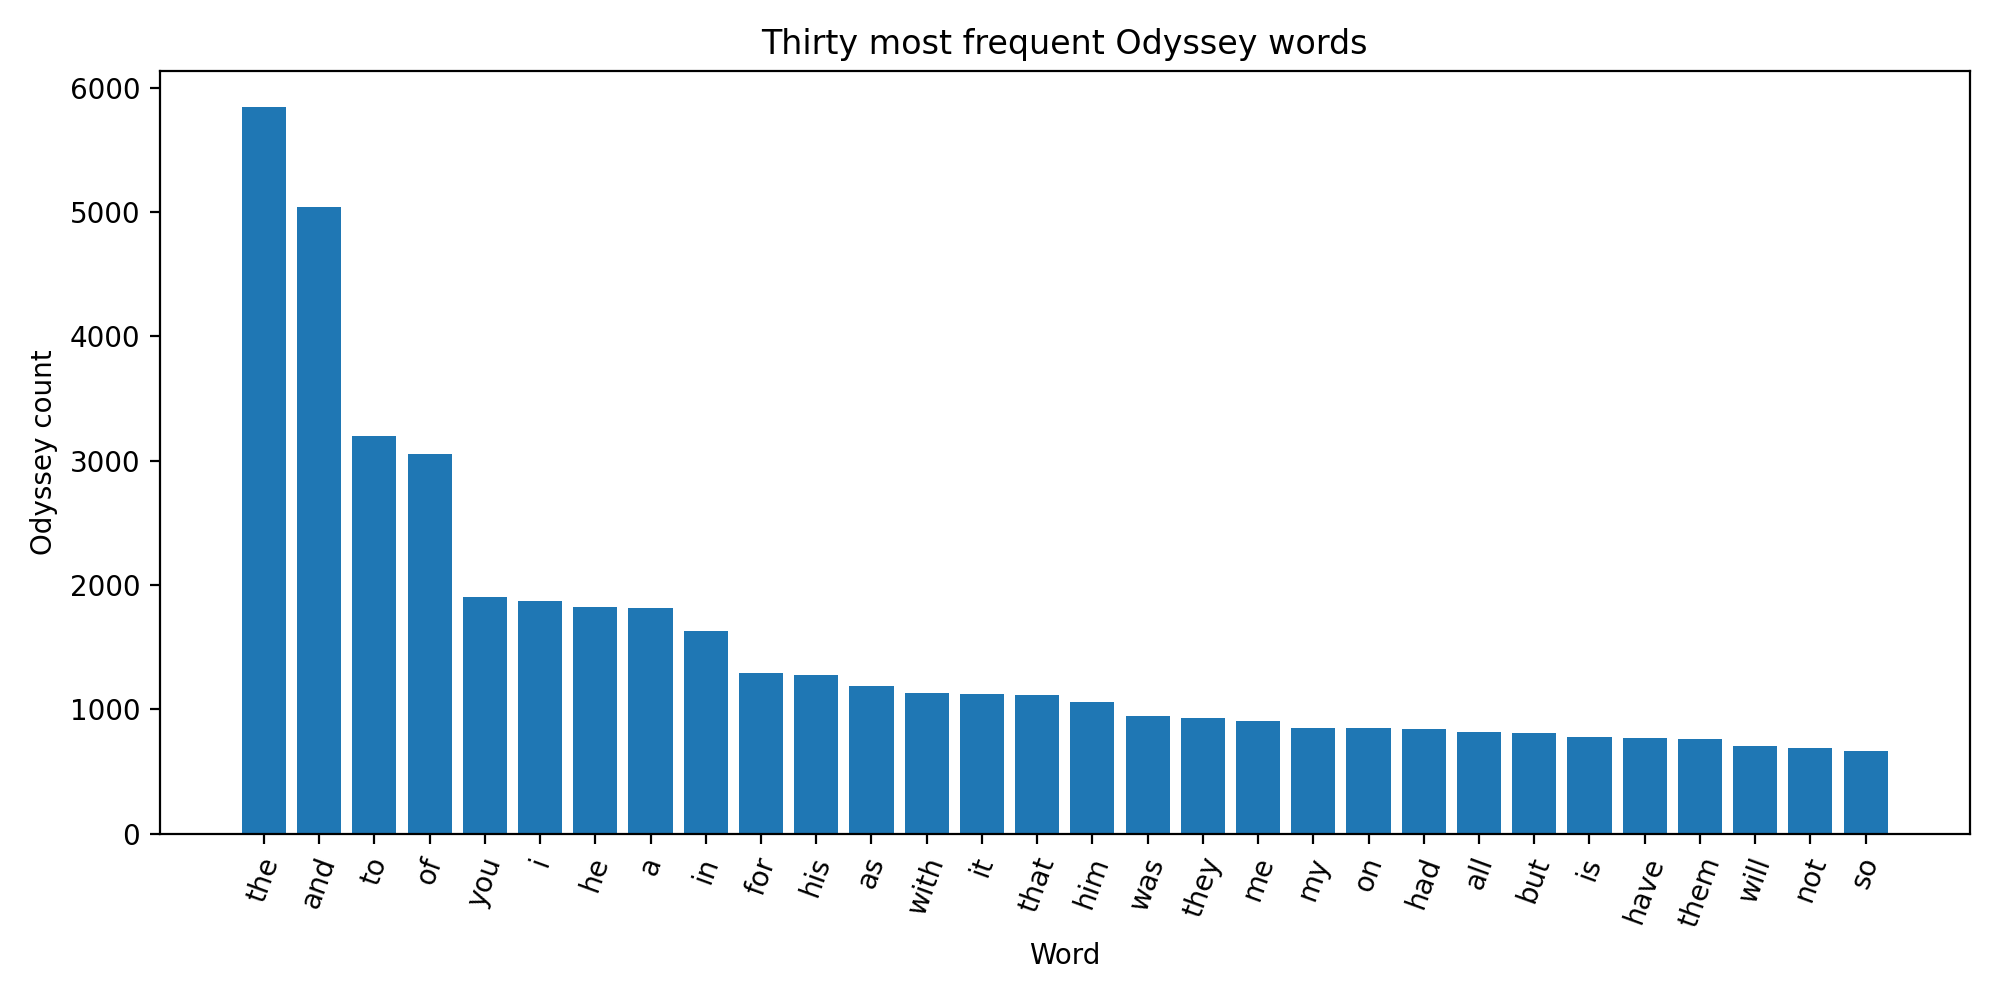

# Task 3 - Conditioned Statistical Generation

Let $P_0(w | u,v)$ be the interpolated Odyssey distribution.

For theme $C$, let $B_C$ be the fixed rewarded-word set.

The conditioned rule is proportional to

$$
P_0(w | u,v)\exp(\lambda)
$$

for a rewarded word, and proportional to

$$
P_0(w | u,v)
$$

otherwise.

The fixed conditioning strength is

$$
\lambda = 1.5.
$$

The implementation uses exact rejection sampling from the base distribution.

For every theme, 500 unconditioned and 500 conditioned sentences were generated using unique deterministic seeds.

Generation stops when the learned end marker is emitted or when the 30-word limit is reached.

A sample that reaches 30 words without the end marker is marked as truncated.

## Fixed displayed examples

Displayed examples were not selected for quality.

For each theme and mode, the notebook chooses the smallest sample index satisfying the predeclared eligibility rule. This avoids favorable example selection after inspecting the generated text.

### discipline

**Marcus passage**

> to a reasonable creature, the same action is both according to nature, and according to reason.

**Unconditioned statistical output**  
Seed: `63875`

> I have left at pylos are already urging her to the town.

**Conditioned statistical output**  
Seed: `73872`

> It was that of ajax who was as fast as he leaned upon his native land showed on the plain was filled with blood.

**Direct LLM output**

> Let the man endure his labour without complaint, keeping his purpose firm though the road be long and the gods send hardship upon him.


### mortality

**Marcus passage**

> the life of such an one, death can never surprise as imperfect; as of an actor, that should die before he had ended, or the play itself were at an end, a man might speak.

**Unconditioned statistical output**  
Seed: `163878`

> He was saying and agreed that i father i have twenty geese about.

**Conditioned statistical output**  
Seed: `173873`

> Surely no man and his acceptance let us a mischief but i was in the house a.

**Direct LLM output**

> No man, though rich in cattle and dear to the gods, may escape the day when death comes and his house is left behind.


### anger

**Marcus passage**

> eighthly, how many things may and do oftentimes follow upon such fits of anger and grief; far more grievous in themselves, than those very things which we are so grieved or angry for.

**Unconditioned statistical output**  
Seed: `263878`

> She held steadily on marrying again let her do all were sitting.

**Conditioned statistical output**  
Seed: `273880`

> As for you are a charlatan or a gold cup to your own inheritance and he with one another.

**Direct LLM output**

> He checked the anger in his heart, for he knew that a rash word may bring more sorrow than the wrong that first provoked it.


### duty

**Marcus passage**

> spend not the remnant of thy days in thoughts and fancies concerning other men, when it is not in relation to some common good, when by it thou art hindered from some other better work.

**Unconditioned statistical output**  
Seed: `363872`

> I am an eagle but your friends again calypso ready to do people.

**Conditioned statistical output**  
Seed: `373872`

> As for my mother answered your questions truly.

**Direct LLM output**

> Then he rose and did the work laid upon him, thinking first of his house and companions rather than of ease or honour.


### self-command

**Marcus passage**

> which thou shalt do; if thou shalt go about every action as thy last action, free from all vanity, all passionate and wilful aberration from reason, and from all hypocrisy, and self-love, and dislike of those things, which by the fates or appointment of god have happened unto thee.

**Unconditioned statistical output**  
Seed: `463876`

> Eumaeus did not enjoy her swear solemnly that she will tell you about wrong that had taken his property during his master's absence.

**Conditioned statistical output**  
Seed: `473872`

> Piraeus was first to ismarus which was not an argive but wept over him.

**Direct LLM output**

> He mastered his heart and held his tongue, waiting until reason showed him when to speak and when to keep silence.

# Task 4 - Three-Way Comparison

The direct LLM receives only the theme label, not the full Marcus passage.

The prompt template is:

> You are given only the theme: `{THEME}`. Write one original sentence of 15 to 30 words that evokes the vocabulary and prose register of Samuel Butler's public-domain English prose translation of the Odyssey. Preserve the ethical direction of the theme where possible. Do not quote or reproduce any specific sentence from the Odyssey or Meditations. Return one sentence only.

The recorded LLM responses are:

**discipline**

> Let the man endure his labour without complaint, keeping his purpose firm though the road be long and the gods send hardship upon him.

**mortality**

> No man, though rich in cattle and dear to the gods, may escape the day when death comes and his house is left behind.

**anger**

> He checked the anger in his heart, for he knew that a rash word may bring more sorrow than the wrong that first provoked it.

**duty**

> Then he rose and did the work laid upon him, thinking first of his house and companions rather than of ease or honour.

**self-command**

> He mastered his heart and held his tongue, waiting until reason showed him when to speak and when to keep silence.

The direct LLM sentences are qualitatively more fluent than most of the statistical examples, but this comparison is illustrative only.

There is one LLM response per theme, while the statistical analysis uses 500 draws per mode and theme.

The LLM also has extensive pretrained linguistic knowledge that the n-gram model does not have.

All 15 displayed outputs were checked against the normalized Odyssey corpus, and none appears as an exact sentence. They are generated inventions, not quotations.

# Task 5 - Did Conditioning Change the Distribution?

The main statistical test compares the conditioned and unconditioned samples using all 500 draws in each group.

The rewarded-word rate is reported in occurrences per 100 generated words.

For a metric $M$, define

$$
D = m_c - m_u
$$

where $m_c$ is the conditioned sample mean and $m_u$ is the unconditioned sample mean.

A fixed-seed nonparametric bootstrap with 2000 resamples gives a 95 percent interval for $D$.

| Theme | Reward rate uncond. | Reward rate cond. | Reward difference | Reward 95% interval | Probe difference | Probe 95% interval | Trunc. uncond. | Trunc. cond. |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| discipline | 0.013 | 0.091 | +0.078 | [0.020, 0.146] | +0.000 | [-0.020, 0.020] | 0.452 | 0.486 |
| mortality | 0.144 | 0.487 | +0.343 | [0.142, 0.530] | -0.018 | [-0.098, 0.065] | 0.472 | 0.466 |
| anger | 0.042 | 0.193 | +0.151 | [0.048, 0.272] | +0.002 | [-0.028, 0.038] | 0.494 | 0.480 |
| duty | 0.019 | 0.263 | +0.244 | [0.003, 0.677] | -0.009 | [-0.086, 0.053] | 0.520 | 0.450 |
| self-command | 0.155 | 0.598 | +0.443 | [0.239, 0.673] | +0.000 | [0.000, 0.000] | 0.458 | 0.446 |

## Explicitly rewarded vocabulary

Every theme has a positive rewarded-word difference, and every rewarded-word 95 percent bootstrap interval lies above zero.

Therefore the conditioning mechanism is measurably operating.

The effect size is still small in absolute frequency. For example, discipline rises by only about 0.078 rewarded words per 100 generated words.

This is expected because the conditioning mechanism directly increases those word probabilities.

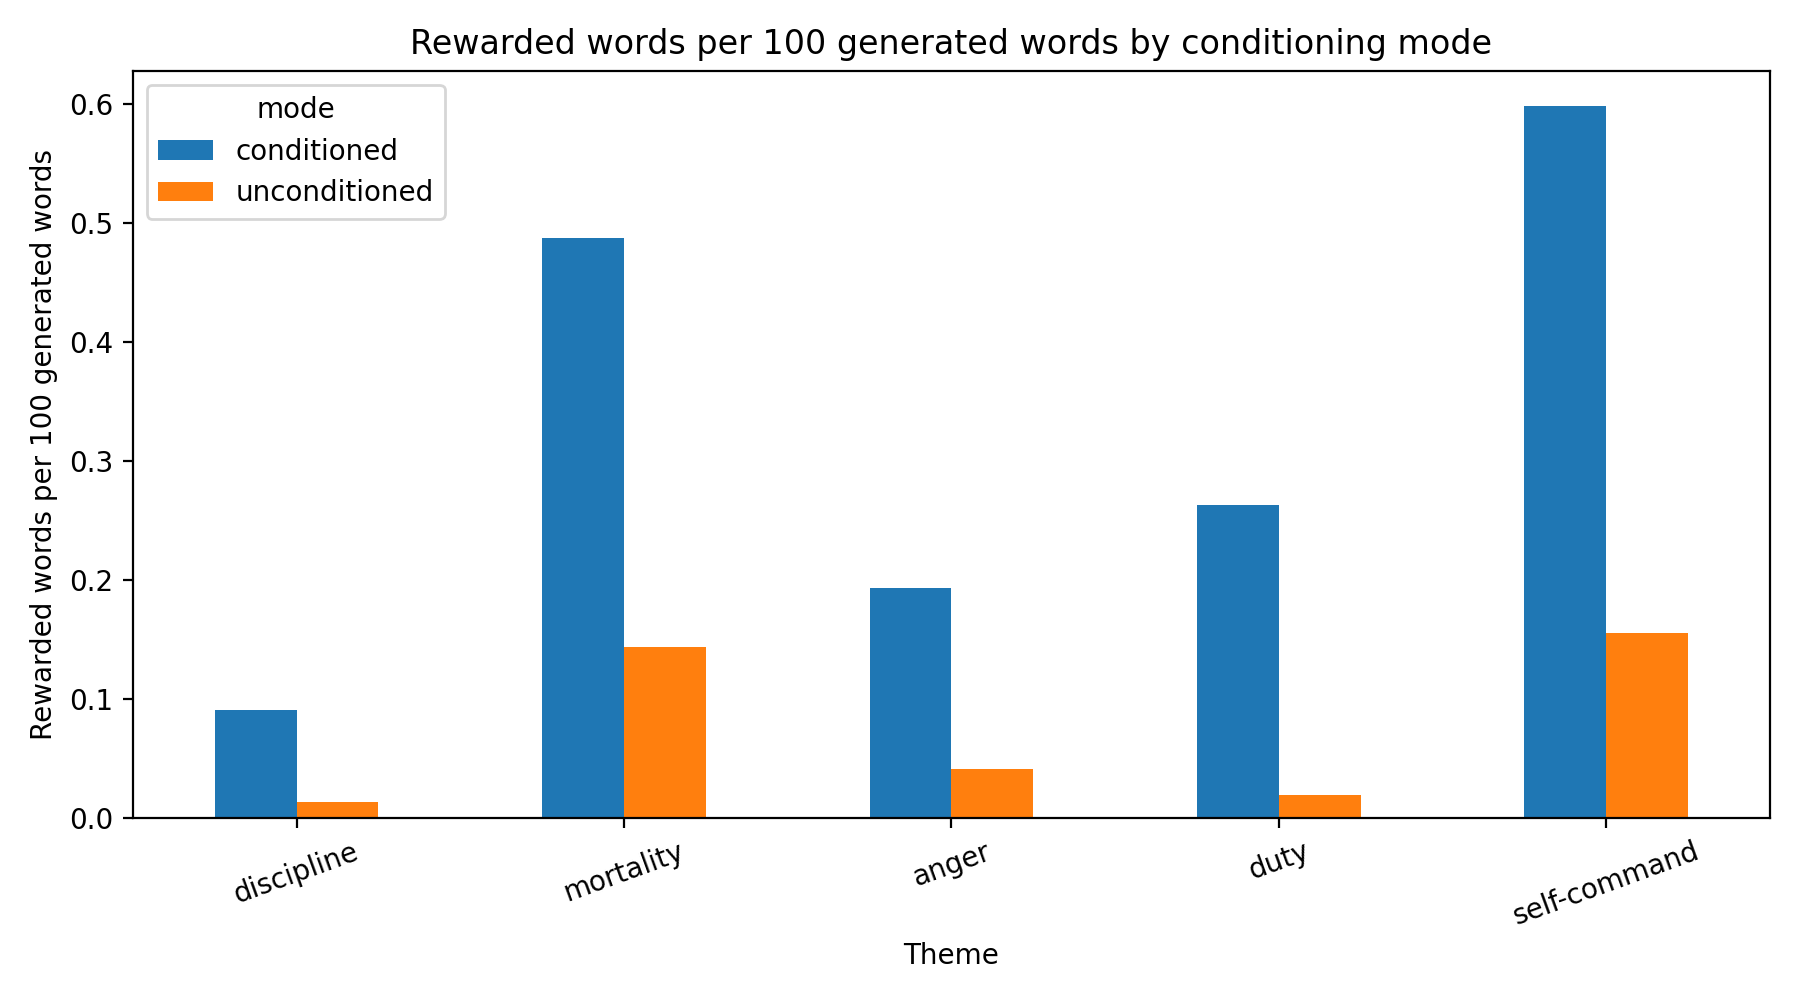

## Unboosted thematic probes

Every probe-word bootstrap interval contains zero.

Therefore the experiment does not show a reliable increase in unboosted thematic vocabulary.

For self-command, the probe rate is zero in both modes for the two probe words that occur in the Odyssey vocabulary.

This result is important because it prevents the direct reward effect from being mistaken for evidence of a broader semantic shift.

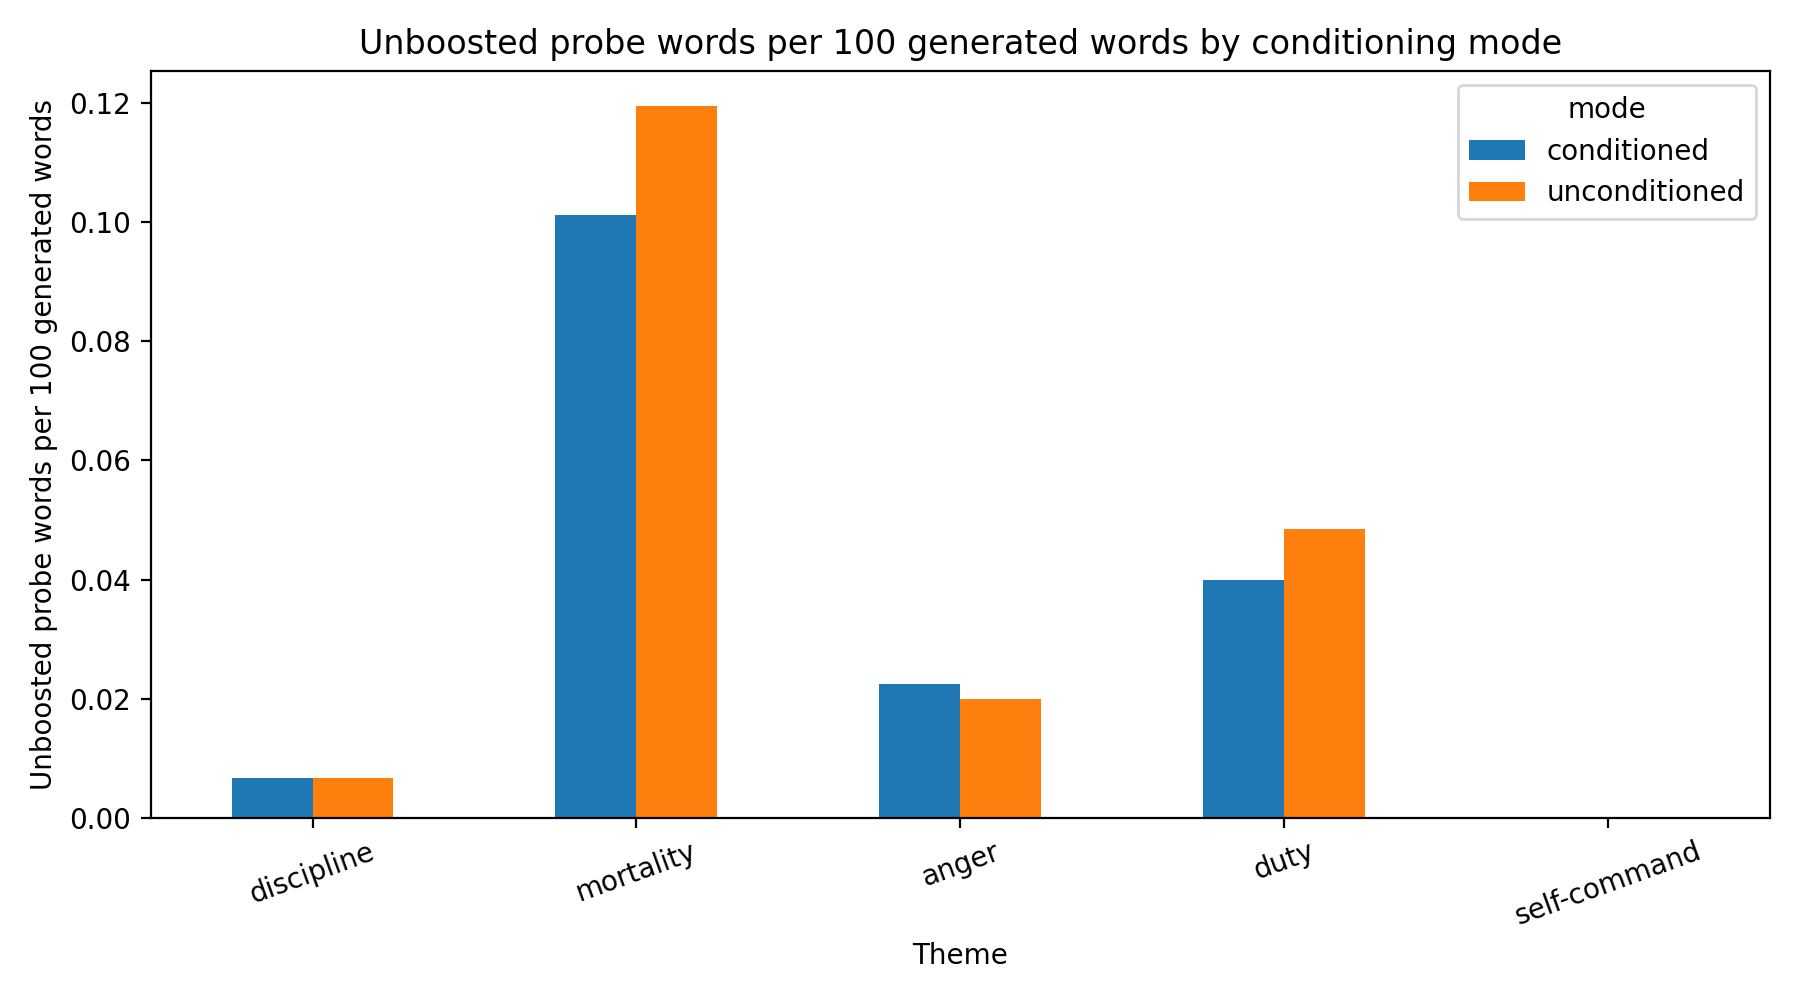

## Jensen-Shannon distance and finite-sample baseline

| Theme | Conditioned vs. unconditioned JS distance |
| --- | --- |
| discipline | 0.340976 |
| mortality | 0.342739 |
| anger | 0.343840 |
| duty | 0.343638 |
| self-command | 0.341311 |

The conditioned-versus-unconditioned Jensen-Shannon distances range from

$$
0.340976
$$

to

$$
0.343840.
$$

However, pairwise comparisons between independent unconditioned groups from the same base generator range from

$$
0.335820
$$

to

$$
0.344813,
$$

with mean

$$
0.340650.
$$

The conditioned distances therefore lie inside the empirical null range.

At this sample size and vocabulary size, the broad unigram Jensen-Shannon distance is dominated by finite-sample sparsity and is not independent evidence of a global lexical shift.

## Sentence length and local Odyssey compatibility

Conditioning does not produce a large systematic change in sentence length.

The local Odyssey bigram-coverage metric also stays almost unchanged.

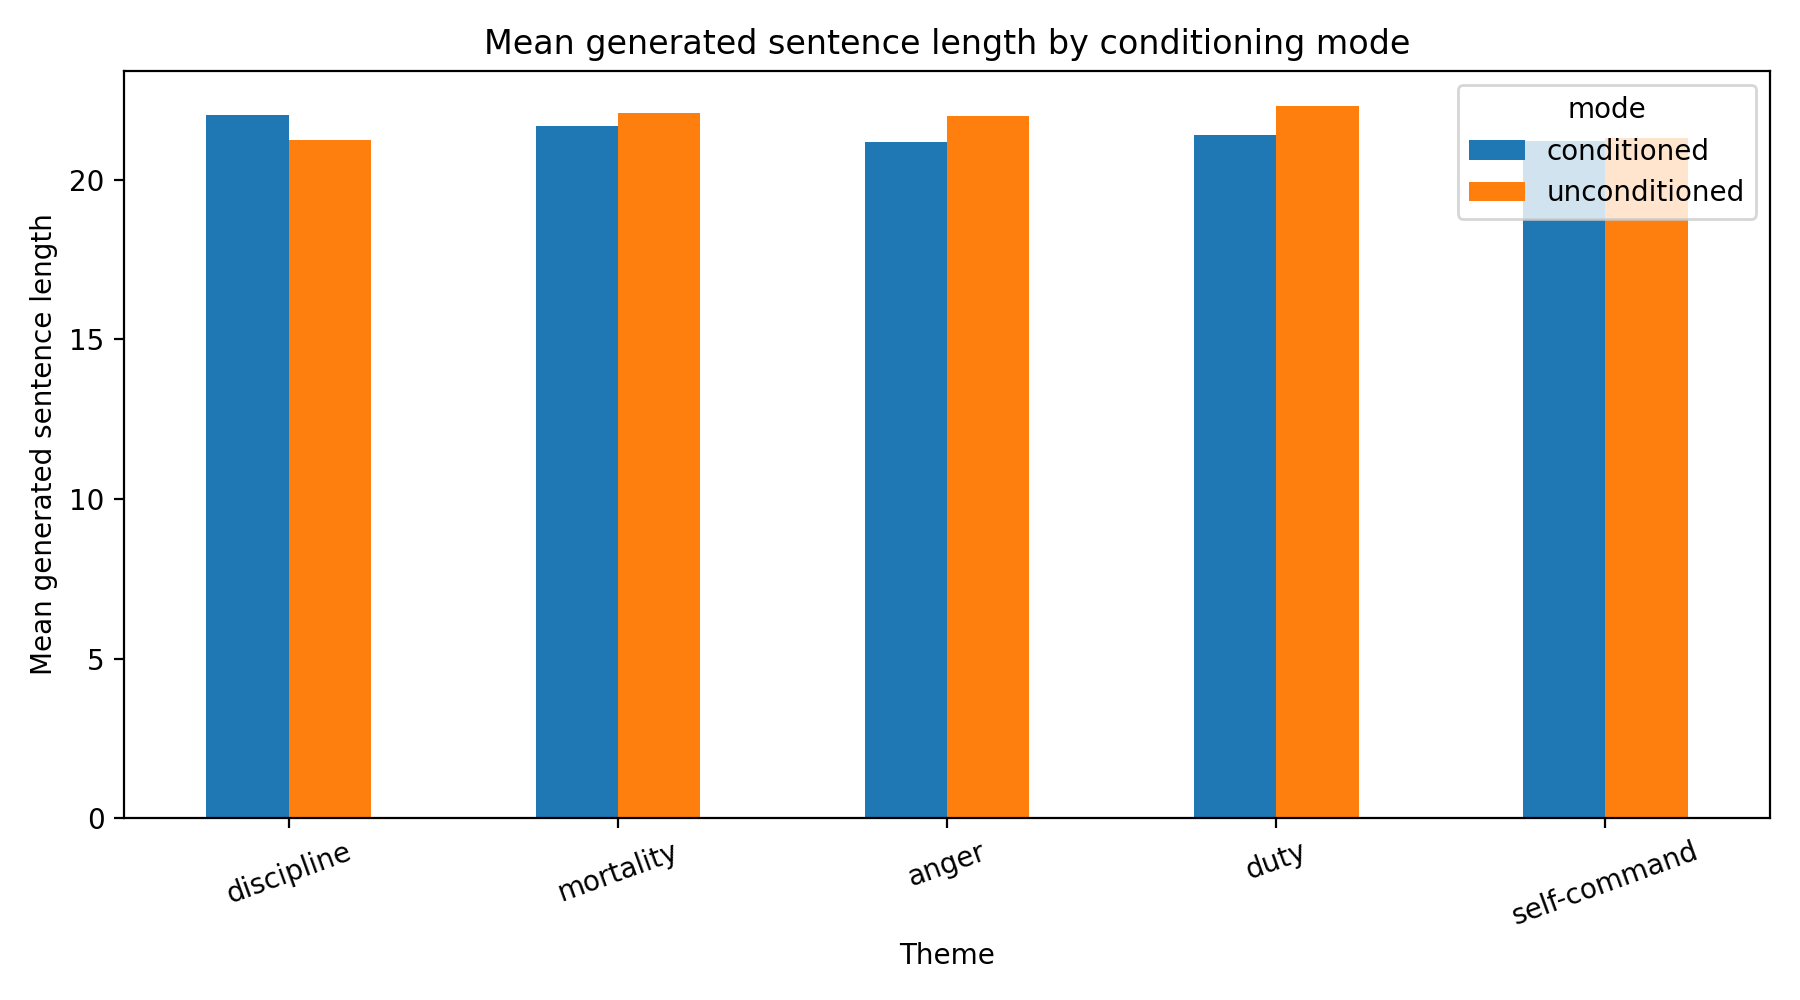

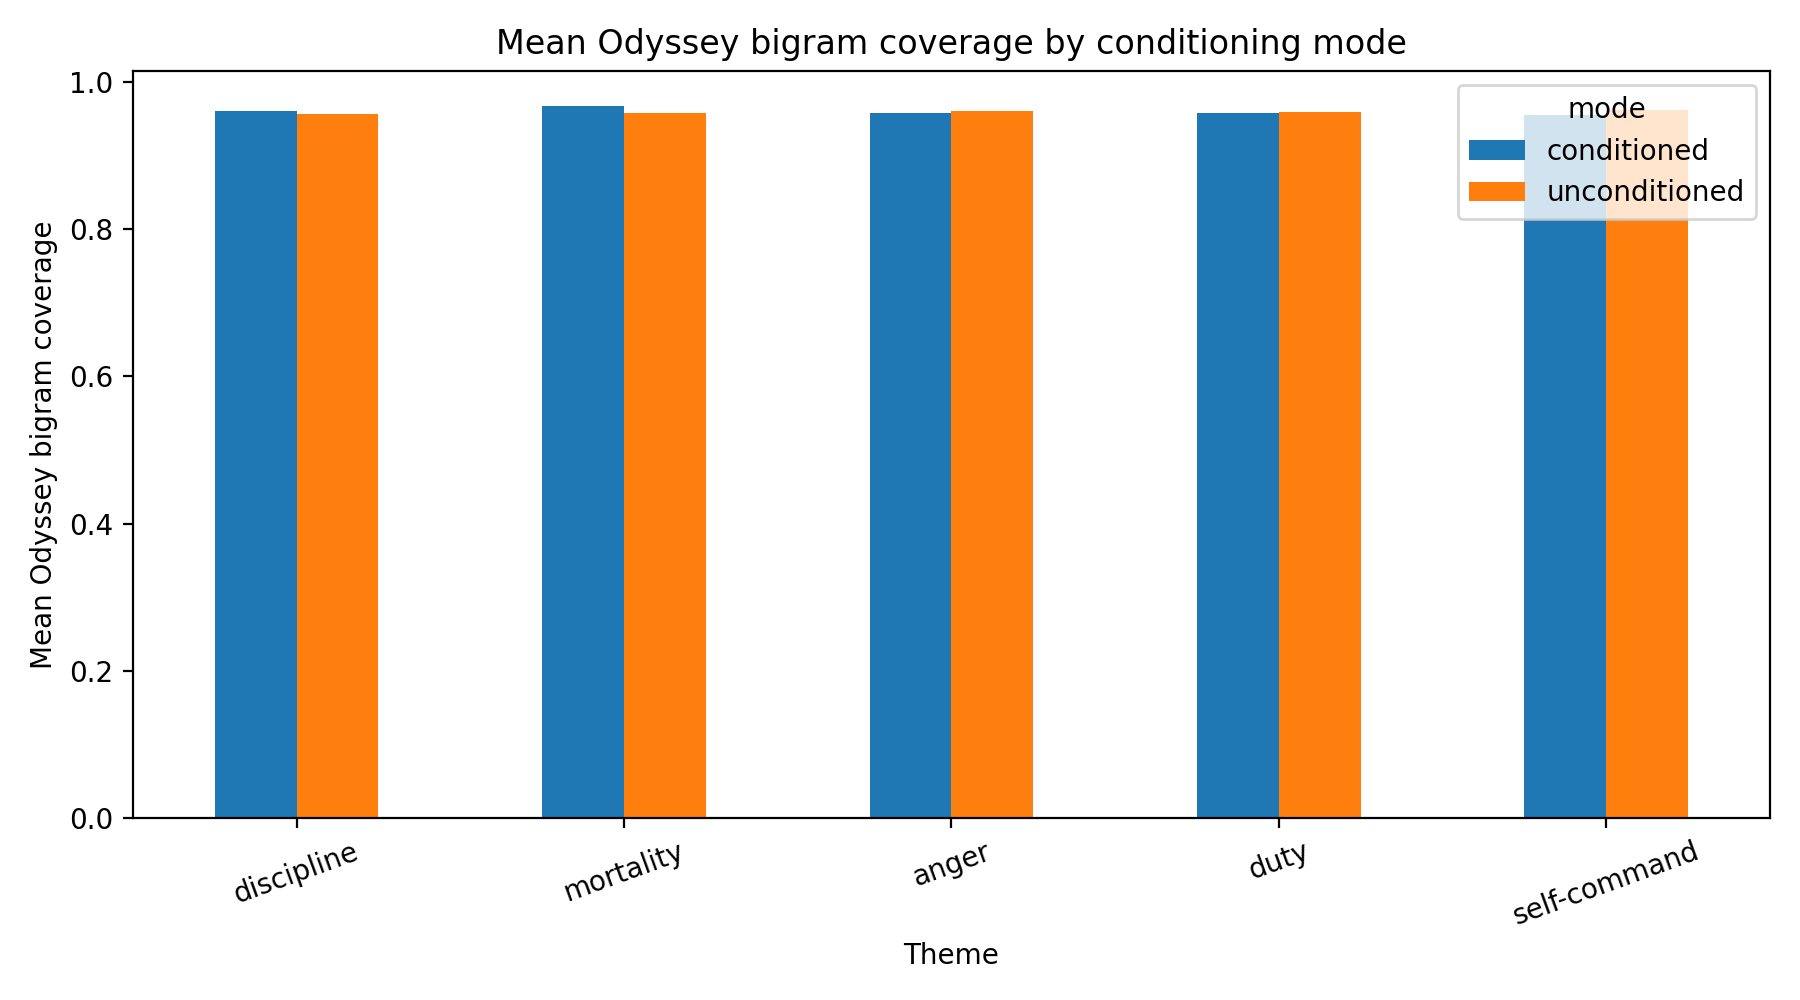

## Overall statistical generation summary

| Mode | Samples | Mean length | Truncation rate | Reward rate | Probe rate | Repeated-bigram fraction | Odyssey bigram coverage |
| --- | --- | --- | --- | --- | --- | --- | --- |
| conditioned | 2500 | 21.503 | 0.466 | 0.326 | 0.034 | 0.0020 | 0.9596 |
| unconditioned | 2500 | 21.792 | 0.479 | 0.075 | 0.039 | 0.0014 | 0.9596 |

The mean Odyssey bigram coverage is approximately 0.96 in both modes.

This shows that most adjacent generated word pairs are observed somewhere in the target corpus.

It does not imply coherent sentences.

The fixed displayed examples show that high local bigram compatibility can coexist with awkward grammar and weak global meaning.

# Task 6 - Failure Analysis

Failures are treated as results rather than being repaired or hidden.

The final analysis reports:

- truncation;
- high internal repeated-bigram rate;
- low Odyssey bigram coverage;
- surface-only theme signal;
- base-Odyssey negative log-likelihood.

| Theme | Mode | N | Truncation | High repetition | Low bigram coverage | Surface-only signal | Mean base NLL |
| --- | --- | --- | --- | --- | --- | --- | --- |
| anger | conditioned | 500 | 0.480 | 0.000 | 0.010 | 0.036 | 2.816 |
| anger | unconditioned | 500 | 0.494 | 0.000 | 0.006 | 0.012 | 2.778 |
| discipline | conditioned | 500 | 0.486 | 0.000 | 0.006 | 0.020 | 2.772 |
| discipline | unconditioned | 500 | 0.452 | 0.000 | 0.008 | 0.004 | 2.833 |
| duty | conditioned | 500 | 0.450 | 0.000 | 0.006 | 0.018 | 2.780 |
| duty | unconditioned | 500 | 0.520 | 0.000 | 0.010 | 0.004 | 2.776 |
| mortality | conditioned | 500 | 0.466 | 0.000 | 0.002 | 0.106 | 2.751 |
| mortality | unconditioned | 500 | 0.472 | 0.000 | 0.008 | 0.018 | 2.815 |
| self-command | conditioned | 500 | 0.446 | 0.000 | 0.008 | 0.110 | 2.824 |
| self-command | unconditioned | 500 | 0.458 | 0.000 | 0.012 | 0.032 | 2.732 |

## Major failure: frequent truncation

Across all themes, about 47.9 percent of unconditioned outputs and 46.6 percent of conditioned outputs reach the 30-word limit before the learned end marker.

The simple generator therefore frequently fails to terminate naturally within the required length.

## Local statistics do not guarantee global quality

The high-repetition flag is zero for every theme and mode, and mean bigram coverage is about 96 percent.

Nevertheless, many fixed-rule examples are grammatically awkward or semantically incoherent.

Local n-gram compatibility is therefore not sufficient evidence of fluent Odyssey-style prose.

## Target-model NLL

Conditioning does not produce a consistent base-Odyssey likelihood benefit or penalty.

The overall mean base-Odyssey NLL is approximately 2.787 for unconditioned output and 2.789 for conditioned output.

The direction varies by theme.

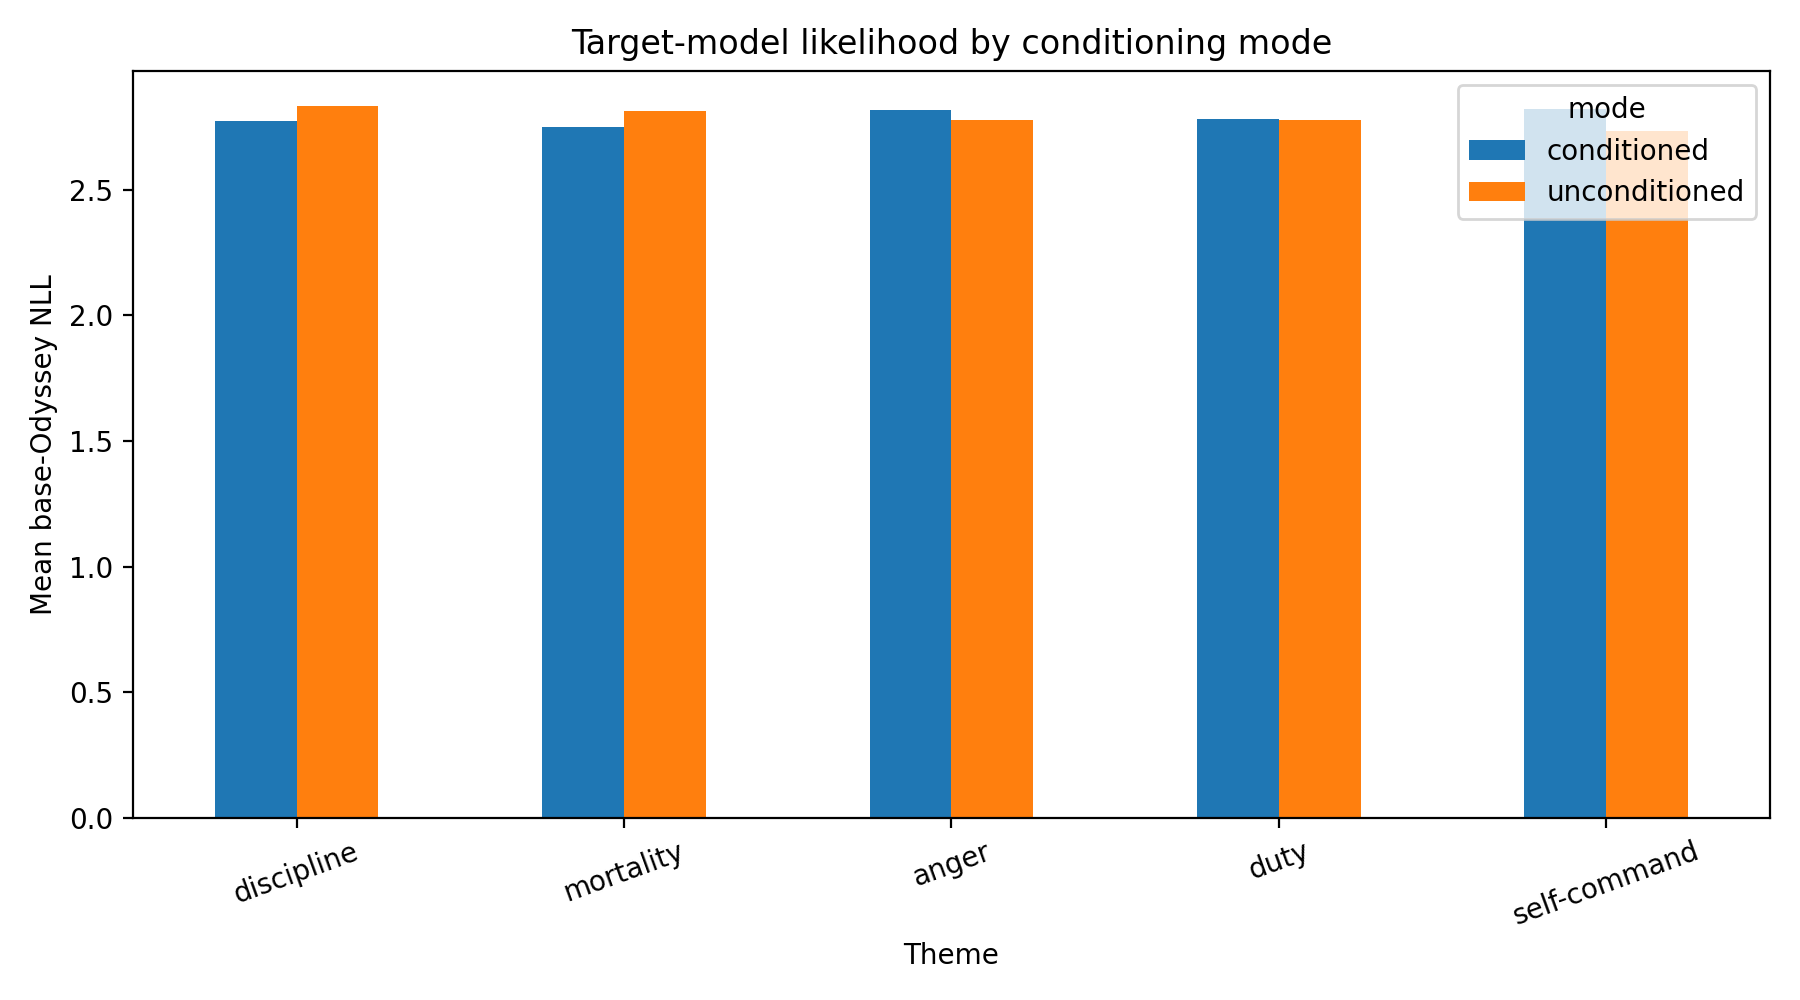

## Surface conditioning versus source meaning

A surface-only theme signal is flagged when a generated sentence contains at least one directly rewarded word but no unboosted probe word.

This flag reaches about:

- 10.6 percent for conditioned mortality;
- 11.0 percent for conditioned self-command.

The flag does not prove semantic failure, but it identifies cases in which the only measured thematic evidence is vocabulary that the conditioning rule directly rewarded.

The deeper limitation is that the statistical generator receives only a theme label.

For the anger theme, for example, increasing `anger`, `wrath`, or `rage` does not preserve a Marcus passage that warns against anger.

The experiment therefore does not justify a semantic accuracy score.

# Final Reflection

The mathematical object in this project is a conditional distribution

$$
P(S | C),
$$

not a deterministic map from one theme to one sentence.

The compiled results show that conditioning changes this distribution in a real but limited way.

Each theme used 500 unconditioned and 500 conditioned statistical draws with fixed seeds. The explicitly rewarded-word rate increased for all five themes, and every 95 percent bootstrap interval for that increase was above zero. The fixed probability bias is therefore measurably operating.

That result should not be confused with preservation of Marcus Aurelius' meaning.

The unboosted probe-word changes are small, and every corresponding bootstrap interval includes zero. The broad unigram Jensen-Shannon distances also fail to provide separate evidence of a global lexical shift because they are comparable to distances between independent unconditioned samples from the same generator.

The failure analysis makes the difference between local style and global quality especially clear. About half of the statistical outputs hit the 30-word limit, even though mean Odyssey bigram coverage is about 96 percent and repeated-bigram failures are essentially absent. High local target-corpus compatibility does not guarantee coherent prose.

The source proposition is also underdetermined by the condition. A label such as `anger` does not say whether Marcus praises anger or counsels restraint. Rewarding topic words can therefore increase surface resemblance while failing to preserve the ethical stance of the passage.

The direct LLM examples are much more fluent qualitatively and usually express a coherent moral stance, but they are not a matched benchmark. There is only one LLM response per theme, and the LLM has extensive pretrained linguistic knowledge. None of the LLM or displayed statistical sentences appears exactly in the Odyssey corpus, so all of them should be treated as generated inventions.

The experiment therefore demonstrates both a success and a failure:

- success: a fixed condition can reproducibly shift a generated distribution;
- failure: a measurable shift can remain shallow and lexical rather than semantic.

For conditioned generation, measurable distributional change and preservation of source meaning must be evaluated separately.

# Overall Conclusion

Homework 7.2 provides a controlled example of conditioned text generation.

The statistical model is intentionally simple, but the experimental design separates several ideas that are easy to confuse:

- explicit conditioning;
- target-corpus local style;
- sentence fluency;
- source-theme vocabulary;
- preservation of source meaning.

The strongest empirical result is that the fixed lexical bias increases the words it explicitly rewards.

The strongest negative result is that this does not produce reliable evidence of broader thematic vocabulary or semantic preservation.

The project therefore supports the central interpretation

$$
P(S | C)
$$

rather than a deterministic condition-to-sentence mapping.

Conditioning changes a distribution, but the scientific question is not only whether the distribution changed. It is whether it changed in the intended, meaningful, and testable way.

# Reproducibility

The final compiled folder contains:

- six task notebooks;
- one reflection notebook;
- the reused Marcus corpus;
- the Butler Odyssey corpus;
- fixed experiment-design metadata;
- the saved n-gram model;
- 5000 statistical generations;
- fixed displayed examples;
- exact LLM prompts and responses;
- bootstrap summaries;
- Jensen-Shannon results and the unconditioned null baseline;
- per-sentence diagnostics;
- failure summaries;
- six final figures.

All generated statistical samples have recorded seeds, and the displayed examples are selected by a rule fixed before output inspection.